# 05 – Evaluation on the Test Set
**IT3091 Machine Learning · Group 2026-DS-02 · Bank Marketing**

The locked hold-out test set (8,236 clients, 20% of the data, never used for any decision so far) is opened **once** to give an
unbiased estimate of how the four tuned models perform on unseen clients.

**Rules:** the models are loaded exactly as saved in `04_modelling` (no retraining, no re-tuning). Decision thresholds are chosen
from **training-set out-of-fold predictions**, never from the test set.

| Section | Content |
|---|---|
| 1 | Setup: load models and test set |
| 2 | Test-set results vs cross-validation |
| 3 | Bootstrap confidence intervals: is RF vs XGBoost really a tie? |
| 4 | ROC, precision–recall and gains curves |
| 5 | Threshold tuning (on training out-of-fold predictions) |
| 6 | Business translation: confusion matrices and call outcomes |
| 7 | Per-year check (time drift) |
| 8 | Save results |
| 9 | Summary |

## 1. Setup: load models and test set

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src import preprocessing as prep
from src import evaluation as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]
COLORS = {"Logistic Regression": "#7f8c8d", "Decision Tree": "#5dade2",
          "Random Forest": "#2e86c1", "XGBoost": "#c0392b"}
models = {name: joblib.load(config.MODELS_DIR / f"{name.lower().replace(' ', '_')}.joblib") for name in MODEL_ORDER}

X_train, X_test, y_train, y_test = prep.load_split()
print("Loaded models:", list(models))
print(f"Train {X_train.shape} | Test {X_test.shape} | test yes-rate {y_test.mean():.2%} ({y_test.sum()} subscribers)")

Loaded models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']
Train (32940, 19) | Test (8236, 19) | test yes-rate 11.27% (928 subscribers)


## 2. Test-set results vs cross-validation
The dummy references are fitted on the training set. Recall / precision / F1 / accuracy use the default 0.5 threshold here
(thresholds are tuned in Section 5). If test scores are close to the CV scores, the CV estimates were reliable and the models generalise.

In [2]:
test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

dummies = {
    "Dummy: always no": Pipeline([("prep", prep.build_preprocessor("tree")),
                                  ("model", DummyClassifier(strategy="most_frequent"))]),
    "Dummy: random guess": Pipeline([("prep", prep.build_preprocessor("tree")),
                                     ("model", DummyClassifier(strategy="stratified", random_state=config.RANDOM_STATE))]),
}
rows = []
for name, d in dummies.items():
    d.fit(X_train, y_train)
    rows.append({"model": name, **ev.score_predictions(y_test, d.predict_proba(X_test)[:, 1])})
for name in MODEL_ORDER:
    rows.append({"model": name, **ev.score_predictions(y_test, test_scores[name])})
test_results = pd.DataFrame(rows).set_index("model")
test_results.drop(columns=["TP", "FP", "FN", "TN"]).round(3)

,pr_auc,roc_auc,precision,recall,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113,0.500,0.000,0.000,0.000,0.500,0.887,0.194
Dummy: random guess,0.116,0.512,0.135,0.133,0.134,0.512,0.807,0.216
Logistic Regression,0.446,0.797,0.338,0.662,0.448,0.749,0.816,0.643
Decision Tree,0.465,0.792,0.303,0.680,0.420,0.741,0.788,0.642
Random Forest,0.496,0.814,0.431,0.637,0.514,0.765,0.864,0.671
XGBoost,0.484,0.814,0.390,0.656,0.490,0.763,0.846,0.665


In [3]:
cv = pd.read_csv(config.RESULTS_DIR / "cv_comparison.csv").set_index("model")
cv_vs_test = pd.DataFrame({
    "CV PR-AUC": cv.loc[MODEL_ORDER, "pr_auc_mean"],
    "CV std": cv.loc[MODEL_ORDER, "pr_auc_std"],
    "Test PR-AUC": test_results.loc[MODEL_ORDER, "pr_auc"],
    "CV ROC-AUC": cv.loc[MODEL_ORDER, "roc_auc_mean"],
    "Test ROC-AUC": test_results.loc[MODEL_ORDER, "roc_auc"],
    "CV top-20%": cv.loc[MODEL_ORDER, "top20_capture_mean"],
    "Test top-20%": test_results.loc[MODEL_ORDER, "top20_capture"],
})
cv_vs_test["Test - CV (PR-AUC)"] = cv_vs_test["Test PR-AUC"] - cv_vs_test["CV PR-AUC"]
cv_vs_test["within 2 std?"] = cv_vs_test["Test - CV (PR-AUC)"].abs() <= 2 * cv_vs_test["CV std"]
cv_vs_test.round(4)

,CV PR-AUC,CV std,Test PR-AUC,CV ROC-AUC,Test ROC-AUC,CV top-20%,Test top-20%,Test - CV (PR-AUC),within 2 std?
model,,,,,,,,,
Logistic Regression,0.4376,0.0125,0.4464,0.7868,0.7968,0.6195,0.6433,0.0088,True
Decision Tree,0.4433,0.0156,0.4646,0.7825,0.7923,0.6249,0.6422,0.0214,True
Random Forest,0.4702,0.0176,0.4955,0.8014,0.8137,0.6430,0.6713,0.0253,True
XGBoost,0.4674,0.0166,0.4844,0.8002,0.8137,0.6421,0.6649,0.0170,True


## 3. Bootstrap confidence intervals
A single test score has uncertainty. The test set is resampled with replacement **1,000 times**, and each model's PR-AUC is recomputed
on every resample. This gives a 95% confidence interval for each model and for the **difference between models**.
If a difference's interval contains 0, the two models cannot be distinguished on this data.

In [4]:
N_BOOT = 1000
rng = np.random.default_rng(config.RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {name: np.empty(N_BOOT) for name in MODEL_ORDER}
start = time.time()
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for name in MODEL_ORDER:
        boot[name][b] = average_precision_score(y_arr[idx], test_scores[name][idx])
print(f"{N_BOOT} bootstrap resamples in {time.time() - start:.0f}s")

def ci(values):
    return np.percentile(values, [2.5, 97.5])

ci_rows = [{"comparison": name, "PR-AUC (test)": test_results.loc[name, "pr_auc"],
            "95% CI low": ci(boot[name])[0], "95% CI high": ci(boot[name])[1]} for name in MODEL_ORDER]
pairs = [("Random Forest", "XGBoost"), ("Random Forest", "Logistic Regression"),
         ("XGBoost", "Logistic Regression"), ("Decision Tree", "Logistic Regression")]
for a, b in pairs:
    diff = boot[a] - boot[b]
    lo, hi = ci(diff)
    ci_rows.append({"comparison": f"{a} - {b}",
                    "PR-AUC (test)": test_results.loc[a, "pr_auc"] - test_results.loc[b, "pr_auc"],
                    "95% CI low": lo, "95% CI high": hi,
                    "share of resamples where first is better": (diff > 0).mean()})
bootstrap_ci = pd.DataFrame(ci_rows).set_index("comparison")
is_diff = bootstrap_ci.index.str.contains(" - ")
excludes_zero = (bootstrap_ci["95% CI low"] > 0) | (bootstrap_ci["95% CI high"] < 0)
bootstrap_ci["difference is significant?"] = np.where(is_diff, np.where(excludes_zero, "yes", "no (CI contains 0)"), "")
bootstrap_ci.round(4)

1000 bootstrap resamples in 24s


,PR-AUC (test),95% CI low,95% CI high,share of resamples where first is better,difference is significant?
comparison,,,,,
Logistic Regression,0.4464,0.4134,0.4824,NaN,
Decision Tree,0.4646,0.4312,0.4994,NaN,
Random Forest,0.4955,0.4605,0.5299,NaN,
XGBoost,0.4844,0.4492,0.5197,NaN,
Random Forest - XGBoost,0.0111,0.0032,0.0187,0.998,yes
Random Forest - Logistic Regression,0.0491,0.0327,0.0658,1.000,yes
XGBoost - Logistic Regression,0.0380,0.0253,0.0524,1.000,yes
Decision Tree - Logistic Regression,0.0182,0.0013,0.0347,0.982,yes


## 4. ROC, precision–recall and gains curves
- **ROC curve:** true-positive rate vs false-positive rate across all thresholds (diagonal = random).
- **Precision–recall curve:** precision vs recall across thresholds (horizontal line at 11.3% = random). Its area is the PR-AUC.
- **Gains chart:** if the bank calls the top *x*% of clients ranked by the model, what share of all subscribers does it reach?
  This is the most direct business view.

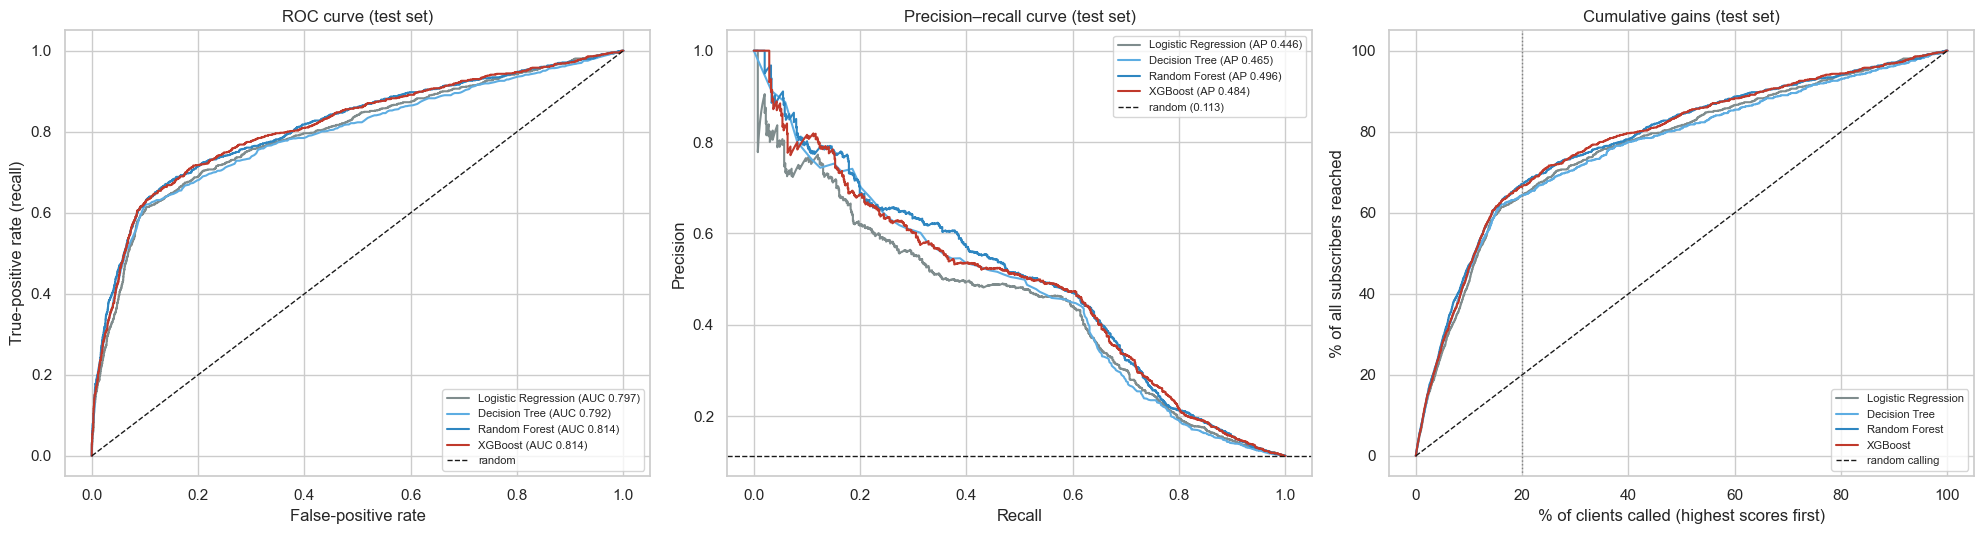

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
base_rate = y_test.mean()
for name in MODEL_ORDER:
    s = test_scores[name]
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=COLORS[name], label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
    order = np.argsort(-s, kind="stable")
    gains = np.concatenate([[0], np.cumsum(y_arr[order]) / y_arr.sum()])
    share = np.arange(len(gains)) / len(y_arr)
    axes[2].plot(share * 100, gains * 100, color=COLORS[name], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="ROC curve (test set)")
axes[1].axhline(base_rate, color="k", ls="--", lw=1, label=f"random ({base_rate:.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve (test set)")
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="random calling")
axes[2].axvline(20, color="grey", ls=":", lw=1)
axes[2].set(xlabel="% of clients called (highest scores first)", ylabel="% of all subscribers reached",
            title="Cumulative gains (test set)")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is not axes[1] else "upper right")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig14_test_roc_pr_gains.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Gains table: share of subscribers reached when calling the top x% of clients
rows = []
for name in MODEL_ORDER:
    row = {"model": name}
    for pct in [10, 20, 30, 40, 50]:
        captured = ev.top_k_capture(y_test, test_scores[name], fraction=pct / 100)
        row[f"top {pct}%"] = captured
    rows.append(row)
gains_table = pd.DataFrame(rows).set_index("model")
gains_table.loc["Random calling"] = [p / 100 for p in [10, 20, 30, 40, 50]]
lift_table = gains_table.div(gains_table.loc["Random calling"], axis=1)
print("Share of all subscribers reached:")
display((100 * gains_table).round(1))
print("Lift over random calling (x times):")
display(lift_table.round(2))

Share of all subscribers reached:


,top 10%,top 20%,top 30%,top 40%,top 50%
model,,,,,
Logistic Regression,43.0,64.3,72.0,77.7,81.6
Decision Tree,45.8,64.2,70.8,77.5,80.8
Random Forest,47.2,67.1,73.8,78.1,84.4
XGBoost,46.3,66.5,74.2,79.6,84.4
Random calling,10.0,20.0,30.0,40.0,50.0


Lift over random calling (x times):


,top 10%,top 20%,top 30%,top 40%,top 50%
model,,,,,
Logistic Regression,4.30,3.22,2.40,1.94,1.63
Decision Tree,4.58,3.21,2.36,1.94,1.62
Random Forest,4.72,3.36,2.46,1.95,1.69
XGBoost,4.63,3.32,2.47,1.99,1.69
Random calling,1.00,1.00,1.00,1.00,1.00


## 5. Threshold tuning (on training out-of-fold predictions)
A threshold turns a score into a call / no-call decision. The default 0.5 has no business meaning (and the class-weighted models'
scores are shifted upwards). Three business rules are compared:

| Rule | Business meaning |
|---|---|
| **Max F1** | Best balance between finding subscribers and avoiding wasted calls |
| **Recall ≥ 70%** | "We want to reach at least 70% of potential subscribers", with the highest precision that achieves it |
| **Capacity 20%** | "The call centre can only call 20% of the client list", so call the top-scored 20% |

**Leakage prevention:** thresholds are chosen from **out-of-fold (OOF) predictions** on the training set. Each training client is
scored by a model that did not see it, using the same 5 folds as before. They are then applied unchanged to the test set.

In [7]:
TARGET_RECALL = 0.70
CAPACITY = 0.20

def pick_thresholds(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]                      # align with thresholds
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return {
        "Max F1": thr[np.argmax(f1)],
        f"Recall >= {TARGET_RECALL:.0%}": thr[rec >= TARGET_RECALL].max(),
        f"Capacity {CAPACITY:.0%}": np.quantile(p, 1 - CAPACITY),
    }

THRESH_MODELS = ["Logistic Regression", "Random Forest", "XGBoost"]
oof, thresholds = {}, {}
for name in THRESH_MODELS:
    start = time.time()
    oof[name] = cross_val_predict(clone(models[name]), X_train, y_train, cv=ev.CV, method="predict_proba")[:, 1]
    thresholds[name] = pick_thresholds(y_train, oof[name])
    print(f"{name:20s} OOF predictions in {time.time() - start:.0f}s | OOF PR-AUC {average_precision_score(y_train, oof[name]):.4f}")

pd.DataFrame(thresholds).T.round(4)

Logistic Regression  OOF predictions in 2s | OOF PR-AUC 0.4355
Random Forest        OOF predictions in 58s | OOF PR-AUC 0.4666
XGBoost              OOF predictions in 25s | OOF PR-AUC 0.4634


,Max F1,Recall >= 70%,Capacity 20%
Logistic Regression,0.6478,0.4131,0.5234
Random Forest,0.5789,0.3644,0.4242
XGBoost,0.6606,0.3934,0.4847


In [8]:
def call_outcome(y, p, t):
    """Business view of a threshold: who gets called and what happens."""
    y = np.asarray(y)
    called = p >= t
    hits = int((called & (y == 1)).sum())
    return {"threshold": t, "% of clients called": 100 * called.mean(), "calls": int(called.sum()),
            "subscribers found": hits, "subscribers missed": int(y.sum() - hits),
            "wasted calls": int(called.sum() - hits),
            "recall": hits / y.sum(), "precision (conversion rate)": hits / max(called.sum(), 1),
            "F1": 2 * hits / (called.sum() + y.sum())}

rows = []
for name in THRESH_MODELS:
    rows.append({"model": name, "rule": "Default 0.5", **call_outcome(y_test, test_scores[name], 0.5)})
    for rule, t in thresholds[name].items():
        rows.append({"model": name, "rule": rule, **call_outcome(y_test, test_scores[name], t)})
rows.append({"model": "Random calling", "rule": "call everyone", **call_outcome(y_test, np.ones(len(y_test)), 0.5)})
threshold_results = pd.DataFrame(rows).set_index(["model", "rule"])
threshold_results.round(3)

threshold  % of clients called  calls  subscribers found  subscribers missed  wasted calls  recall  precision (conversion rate)     F1
model               rule                                                                                                                                                 
Logistic Regression Default 0.5        0.500               22.050   1816                614                 314          1202   0.662                        0.338  0.448
                    Max F1             0.648               14.546   1198                545                 383           653   0.587                        0.455  0.513
                    Recall >= 70%      0.413               30.427   2506                670                 258          1836   0.722                        0.267  0.390
                    Capacity 20%       0.523               20.265   1669                599                 329          1070   0.645                        0.359  0.461
Random Forest       Default 0.5        0.500               16.646   1371                591                 337           780   0.637                        0.431  0.514
                    Max F1             0.579               14.643   1206                563                 365           643   0.607                        0.467  0.528
                    Recall >= 70%      0.364               28.011   2307                679                 249          1628   0.732                        0.294  0.420
                    Capacity 20%       0.424               20.070   1653                623                 305          1030   0.671                        0.377  0.483
XGBoost             Default 0.5        0.500               18.941   1560                609                 319           951   0.656                        0.390  0.490
                    Max F1             0.661               13.987   1152                548                 380           604   0.591                        0.476  0.527
                    Recall >= 70%      0.393               27.428   2259                670                 258          1589   0.722                        0.297  0.420
                    Capacity 20%       0.485               19.815   1632                616                 312          1016   0.664                        0.377  0.481
Random calling      call everyone      0.500              100.000   8236                928                   0          7308   1.000                        0.113  0.203

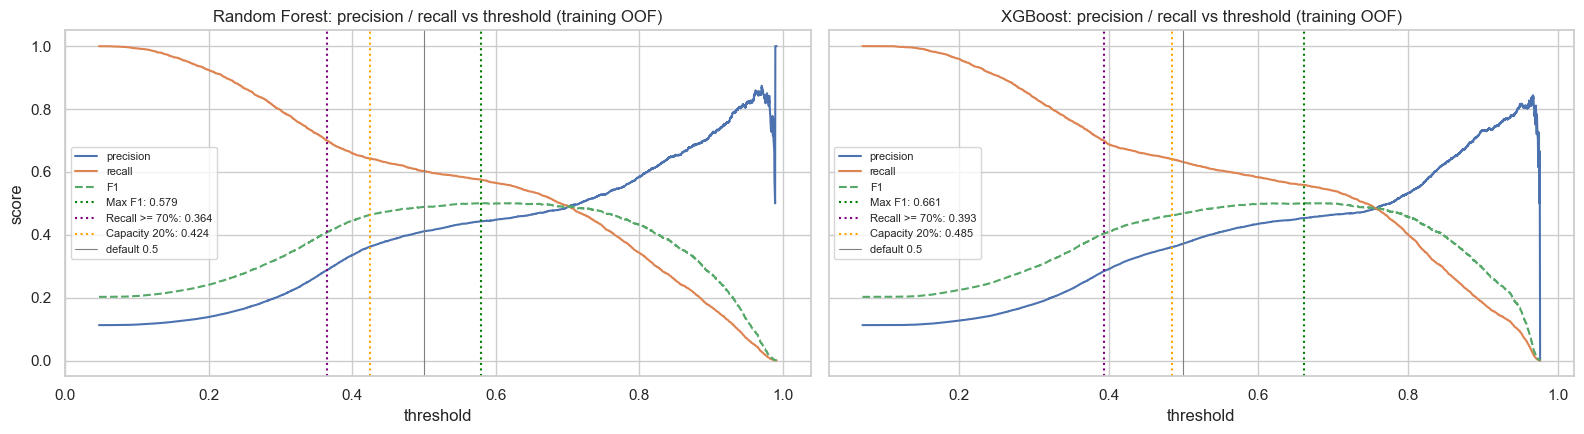

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    prec, rec, thr = precision_recall_curve(y_train, oof[name])
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    ax.plot(thr, prec[:-1], label="precision")
    ax.plot(thr, rec[:-1], label="recall")
    ax.plot(thr, f1, label="F1", ls="--")
    for (rule, t), c in zip(thresholds[name].items(), ["green", "purple", "orange"]):
        ax.axvline(t, color=c, ls=":", lw=1.5, label=f"{rule}: {t:.3f}")
    ax.axvline(0.5, color="grey", ls="-", lw=0.8, label="default 0.5")
    ax.set(xlabel="threshold", title=f"{name}: precision / recall vs threshold (training OOF)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("score")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig15_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Business translation: confusion matrices
Confusion matrices on the test set for the two shortlisted models at the **Max F1** threshold (from training OOF), compared with calling everyone.

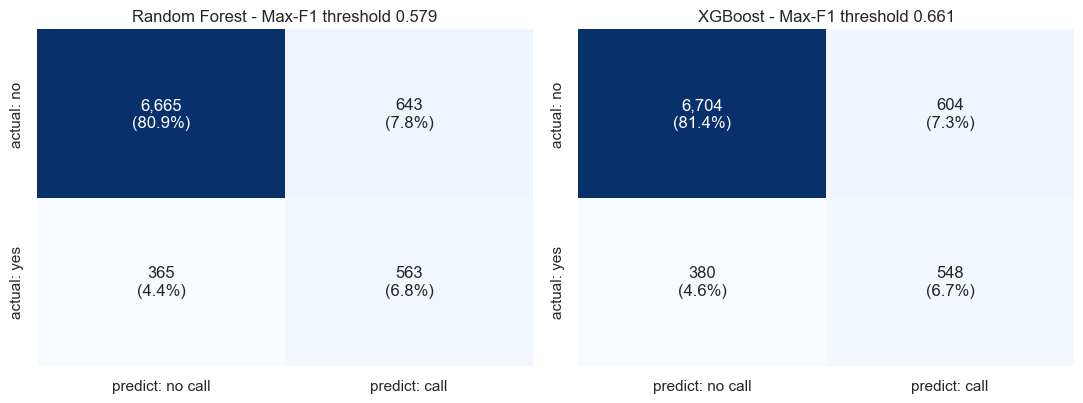

Call everyone: 8,236 calls -> 928 subscribers (conversion 11.3%)
Random Forest Max F1       : 1,206 calls (14.6% of list) -> 563 subscribers (60.7% of all), conversion 46.7% = 4.1x calling everyone
Random Forest Capacity 20% : 1,653 calls (20.1% of list) -> 623 subscribers (67.1% of all), conversion 37.7% = 3.3x calling everyone
XGBoost       Max F1       : 1,152 calls (14.0% of list) -> 548 subscribers (59.1% of all), conversion 47.6% = 4.2x calling everyone
XGBoost       Capacity 20% : 1,632 calls (19.8% of list) -> 616 subscribers (66.4% of all), conversion 37.7% = 3.3x calling everyone


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    t = thresholds[name]["Max F1"]
    cm = confusion_matrix(y_test, (test_scores[name] >= t).astype(int), labels=[0, 1])
    labels = np.array([[f"{v:,}\n({v / cm.sum():.1%})" for v in r] for r in cm])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["predict: no call", "predict: call"], yticklabels=["actual: no", "actual: yes"])
    ax.set_title(f"{name} - Max-F1 threshold {t:.3f}")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig16_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

everyone = call_outcome(y_test, np.ones(len(y_test)), 0.5)
print(f"Call everyone: {everyone['calls']:,} calls -> {everyone['subscribers found']} subscribers "
      f"(conversion {everyone['precision (conversion rate)']:.1%})")
for name in ["Random Forest", "XGBoost"]:
    for rule in ["Max F1", f"Capacity {CAPACITY:.0%}"]:
        r = threshold_results.loc[(name, rule)]
        print(f"{name:13s} {rule:13s}: {int(r['calls']):,} calls ({r['% of clients called']:.1f}% of list) -> "
              f"{int(r['subscribers found'])} subscribers ({r['recall']:.1%} of all), conversion "
              f"{r['precision (conversion rate)']:.1%} = {r['precision (conversion rate)'] / everyone['precision (conversion rate)']:.1f}x calling everyone")

## 7. Per-year check (time drift)
Validation (`03_validation`) showed predicting a *future* period is much harder. Here we check how well the models rank clients
**within each year** of the test set. ROC-AUC is used because it is not affected by the very different yes-rates per year;
PR-AUC lift = PR-AUC ÷ that year's yes-rate.
The year is reconstructed from the date order of the rows (analysis only, never a model feature).

In [11]:
clean, Xtr_pos, Xte_pos, ytr_pos, yte_pos = prep.recreate_split_with_positions()
pd.testing.assert_frame_equal(Xte_pos.reset_index(drop=True), X_test, check_dtype=False)
test_year = prep.reconstruct_year(clean["month"]).loc[Xte_pos.index].to_numpy()

rows = []
for year in sorted(np.unique(test_year)):
    mask = test_year == year
    yy = y_arr[mask]
    row = {"year": year, "test rows": int(mask.sum()), "yes-rate %": round(100 * yy.mean(), 2)}
    for name in MODEL_ORDER:
        row[f"{name} ROC-AUC"] = round(roc_auc_score(yy, test_scores[name][mask]), 3)
    for name in MODEL_ORDER:
        row[f"{name} PR-AUC lift"] = round(average_precision_score(yy, test_scores[name][mask]) / yy.mean(), 2)
    rows.append(row)
per_year = pd.DataFrame(rows).set_index("year")
per_year.T

year,2008,2009,2010
test rows,5566.000,2277.000,393.000
yes-rate %,4.490,20.600,53.180
Logistic Regression ROC-AUC,0.560,0.755,0.688
Decision Tree ROC-AUC,0.537,0.770,0.742
Random Forest ROC-AUC,0.588,0.790,0.744
XGBoost ROC-AUC,0.589,0.784,0.730
Logistic Regression PR-AUC lift,1.290,2.150,1.330
Decision Tree PR-AUC lift,1.500,2.210,1.410
Random Forest PR-AUC lift,2.210,2.420,1.450
XGBoost PR-AUC lift,2.130,2.330,1.430


## 8. Save results

In [12]:
test_results.to_csv(config.RESULTS_DIR / "test_results.csv")
cv_vs_test.to_csv(config.RESULTS_DIR / "cv_vs_test.csv")
bootstrap_ci.to_csv(config.RESULTS_DIR / "bootstrap_ci.csv")
gains_table.to_csv(config.RESULTS_DIR / "gains_table.csv")
threshold_results.to_csv(config.RESULTS_DIR / "threshold_results.csv")
pd.DataFrame(thresholds).T.to_csv(config.RESULTS_DIR / "thresholds_from_oof.csv")
per_year.to_csv(config.RESULTS_DIR / "per_year_test.csv")
print(sorted(p.name for p in config.RESULTS_DIR.iterdir()))

['best_params.json', 'bootstrap_ci.csv', 'cv_comparison.csv', 'cv_vs_test.csv', 'gains_table.csv', 'overfitting_check.csv', 'per_year_test.csv', 'test_results.csv', 'threshold_results.csv', 'thresholds_from_oof.csv', 'tuning_decision_tree.csv', 'tuning_logistic_regression.csv', 'tuning_random_forest.csv', 'tuning_xgboost.csv']


## 9. Summary
Full details: `docs/evaluation_findings.txt`.

**Test results (8,236 unseen clients, 928 subscribers)**
| Model | PR-AUC [95% CI] | ROC-AUC | Top-10% | Top-20% | Test − CV PR-AUC |
|---|---|---|---|---|---|
| Random guess | 0.116 | 0.512 | 10% | 22% | – |
| Logistic Regression (baseline) | 0.446 [0.413, 0.482] | 0.797 | 43.0% | 64.3% | +0.009 |
| Decision Tree | 0.465 [0.431, 0.499] | 0.792 | 45.8% | 64.2% | +0.021 |
| **Random Forest** | **0.496 [0.461, 0.530]** | **0.814** | **47.2%** | **67.1%** | +0.025 |
| XGBoost | 0.484 [0.449, 0.520] | **0.814** | 46.3% | 66.5% | +0.017 |

- **The models generalise:** every test score lies within 2 CV standard deviations of its CV estimate (all slightly higher, consistent with normal sampling variation). CV was a reliable guide and nothing was over-tuned.
- **Ranking is unchanged from CV:** RF > XGBoost > DT > LR. On the test set the bootstrap shows **RF beats XGBoost by +0.011 PR-AUC (95% CI 0.003–0.019, better in 99.8% of resamples)**. The gap is statistically detectable but small in practical terms (≈ 1 point); in CV they were tied (Δ 0.003). RF and XGBoost both clearly beat the baseline (+0.049 / +0.038, CIs well above 0). DT − LR is borderline (CI lower bound 0.001).
- **Business value (gains):** calling the top 10% of RF-ranked clients reaches **47% of subscribers (4.7× random)**; the top 20% reaches **67% (3.4×)**; the top 50% reaches 84%.

**Thresholds (chosen on training OOF predictions, applied unchanged to test)**: they transfer well to the test set (the capacity rule called 20.1% of clients; the recall ≥ 70% rule achieved 72–73% recall).
| Random Forest rule | Threshold | % called | Subscribers found | Conversion | vs calling everyone |
|---|---|---|---|---|---|
| Max F1 | 0.579 | 14.6% | 563 / 928 (60.7%) | 46.7% | 4.1× |
| Capacity 20% | 0.424 | 20.1% | 623 (67.1%) | 37.7% | 3.3× |
| Recall ≥ 70% | 0.364 | 28.0% | 679 (73.2%) | 29.4% | 2.6× |
| Call everyone | – | 100% | 928 | 11.3% | 1× |
- The default 0.5 threshold is not optimal; Max F1 improves F1 for all three models. The F1 curve is **flat over a wide range (~0.45–0.70)**, so the exact threshold is not critical, and the rule can be chosen for business reasons (call-centre capacity vs target reach).

**Per-year check (time drift)**: within-year ranking is weaker than the overall ROC-AUC of 0.81.
| Year (test rows, yes-rate) | LR | DT | RF | XGB |
|---|---|---|---|---|
| 2008 (5,566, 4.5%) | 0.560 | 0.537 | **0.588** | **0.589** |
| 2009 (2,277, 20.6%) | 0.755 | 0.770 | **0.790** | 0.784 |
| 2010 (393, 53.2%) | 0.688 | 0.742 | **0.744** | 0.730 |
- The overall 0.81 is higher than within any single year because part of the model's skill is **separating good periods from bad periods** (economic conditions), not only good clients from bad clients.
- **Within 2008** (the first campaign period, almost no previous-contact history) ranking is weak (≈ 0.59); it is much better once campaign history exists (2009: 0.79). RF is best or tied best in every year (2008 PR-AUC lift 2.21 vs 1.29 for LR).
- This confirms the Step 4 limitation: the model works best when trained on recent data that includes client contact history, and must be retrained as conditions change.